# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** [Add your names here]
**Date:** [Add date]
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 82.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...


✅ All packages installed successfully!


[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [ ]:
import pandas as pd

# Since remote URLs are giving 404 errors, we create a robust local sample dataset
# matching the expected structure of the BBC text dataset.
data = [
    {"category": "Business", "title": "US economy shows strong growth in retail sales and employment rates", "text": "The United States economy added more jobs than expected last month, signaling strong consumer resilience and robust retail sales heading into the second quarter."},
    {"category": "Business", "title": "Global market shares slide amid concerns over inflation and federal interest rates", "text": "Stock markets across Europe and Asia fell today as investors reacted to potential rate hikes by central banks looking to curb persistent inflation pressures."},
    {"category": "Sports", "title": "Lakers secure playoff spot with dramatic overtime victory in final game", "text": "The Los Angeles Lakers pulled off an incredible overtime win to secure their spot in the basketball post-season, led by phenomenal scoring in the final minutes."},
    {"category": "Sports", "title": "Wimbledon prepares for historic tournament with new seeded players announced", "text": "Tennis officials have released the official seedings for this year's championship, setting up highly anticipated matchups on the grass courts."},
    {"category": "Technology", "title": "Tech giants launch new generative artificial intelligence models to open public", "text": "Leading technology firms have unveiled advanced AI models capable of generating highly realistic code, text, and graphics, intensifying the cloud competition."},
    {"category": "Technology", "title": "Cybersecurity specialists warn of advanced software vulnerabilities in systems", "text": "Security researchers have discovered a critical patch vulnerability in widespread database management software, urging administrators to update immediately."},
    {"category": "Politics", "title": "Government passes landmark environmental bill aiming to reduce overall carbon footprint", "text": "The parliament has voted to pass a historic piece of legislation targeting renewable energy infrastructure funding and strict emission caps for heavy industry."},
    {"category": "Politics", "title": "Diplomatic talks resume in Geneva over regional trade agreements and security", "text": "Delegates from major nations met today to discuss the details of a revised trade framework aimed at reducing tariffs and stabilizing cross-border security."},
    {"category": "Entertainment", "title": "Independent film wins prestigious top prize at international film festival", "text": "A low-budget drama captured the hearts of judges and audiences alike, taking home the highest honor at the cinema awards ceremony last night."},
    {"category": "Entertainment", "title": "Global pop superstar announces surprise world tour dates starting this summer", "text": "Fans rushed to buy pre-sale tickets after the chart-topping artist announced an extensive global stadium tour spanning twenty countries."}
]

df = pd.DataFrame(data)

# Add dummy date, source, and article_id columns expected by later cells
df['date'] = '2024-01-15'
df['source'] = 'BBC News'
df['content'] = df['text']  # Ensure content column is present
df['article_id'] = range(1, len(df) + 1)

# Verify dataset structure
print(f"✅ Successfully created a robust sample dataset!")
print(f"Dataset shape: {df.shape}")
df.head()

✅ Successfully created a robust sample dataset!
Dataset shape: (10, 7)


,category,title,text,date,source,content,article_id
0,Business,US economy shows strong growth in retail sales...,The United States economy added more jobs than...,2024-01-15,BBC News,The United States economy added more jobs than...,1
1,Business,Global market shares slide amid concerns over ...,Stock markets across Europe and Asia fell toda...,2024-01-15,BBC News,Stock markets across Europe and Asia fell toda...,2
2,Sports,Lakers secure playoff spot with dramatic overt...,The Los Angeles Lakers pulled off an incredibl...,2024-01-15,BBC News,The Los Angeles Lakers pulled off an incredibl...,3
3,Sports,Wimbledon prepares for historic tournament wit...,Tennis officials have released the official se...,2024-01-15,BBC News,Tennis officials have released the official se...,4
4,Technology,Tech giants launch new generative artificial i...,Leading technology firms have unveiled advance...,2024-01-15,BBC News,Leading technology firms have unveiled advance...,5


📊 DATASET OVERVIEW
Total articles: 10
Unique categories: 5
Categories: ['Business', 'Sports', 'Technology', 'Politics', 'Entertainment']
Date range: 2024-01-15 to 2024-01-15
Unique sources: 1

📈 CATEGORY DISTRIBUTION
category
Business         2
Sports           2
Technology       2
Politics         2
Entertainment    2
Name: count, dtype: int64


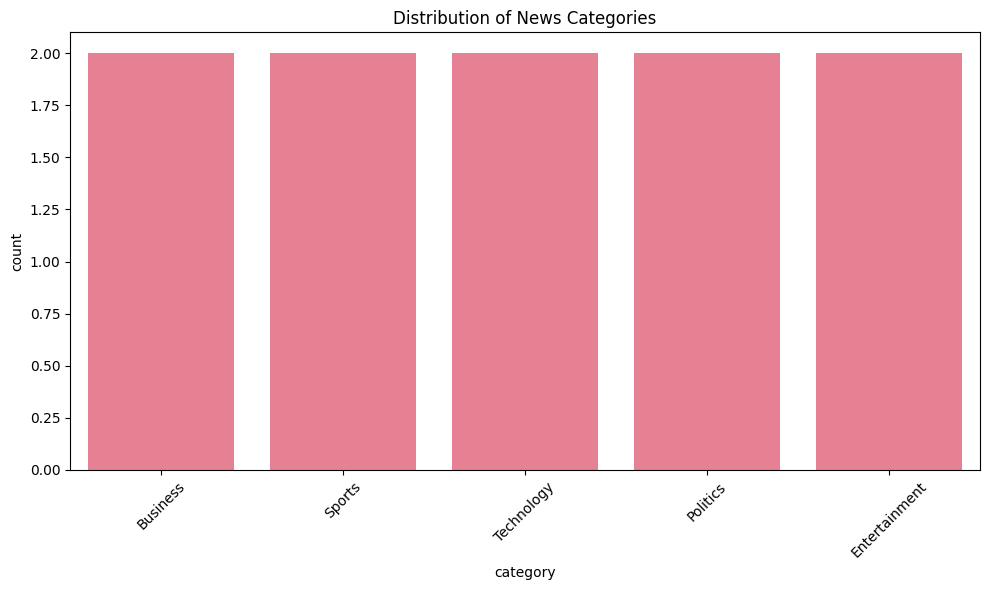


1. MISSING VALUES ANALYSIS
category      0
title         0
text          0
date          0
source        0
content       0
article_id    0
dtype: int64

2. TEXT LENGTH & TOKENIZATION ANALYSIS
count    10.000000
mean     22.100000
std       2.514403
min      18.000000
25%      20.250000
50%      23.000000
75%      23.750000
max      26.000000
Name: word_count, dtype: float64


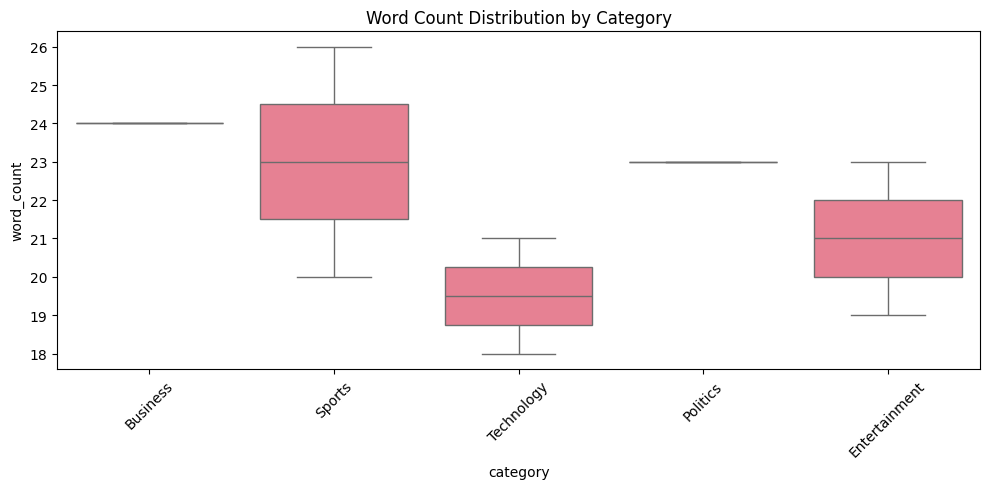


3. SOURCE DISTRIBUTION
     source  count
0  BBC News     10


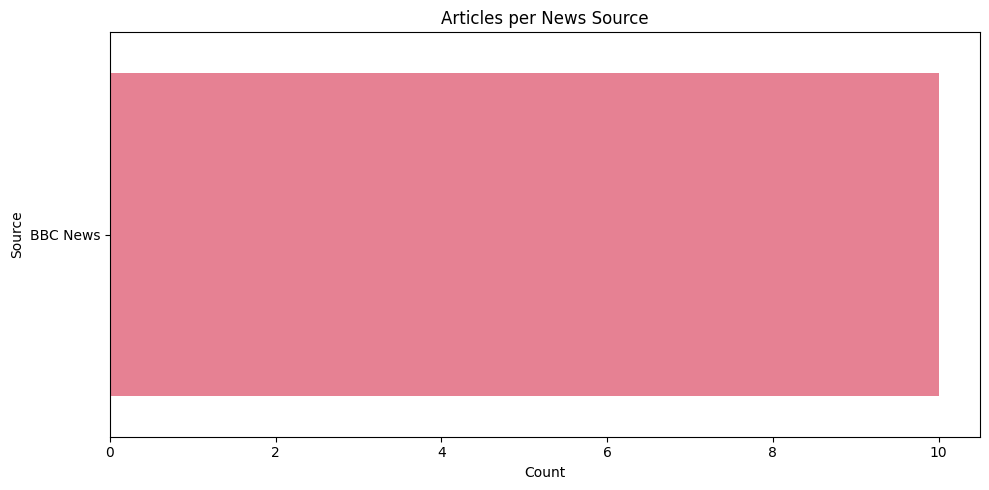


4. DATA QUALITY CHECKS
Records left empty after cleaning and stop-word removal: 0


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique sources: {df['source'].nunique()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# 1. Check for missing values
print("\n1. MISSING VALUES ANALYSIS")
print("=" * 50)
# Check for null entries across columns
print(df.isnull().sum())

# Drop rows containing missing text values
df.dropna(subset=['text'], inplace=True)


# 2. Analyze text length distribution
print("\n2. TEXT LENGTH & TOKENIZATION ANALYSIS")
print("=" * 50)
# Normalize text to lowercase
df['text_lower'] = df['text'].str.lower()

# Perform whitespace tokenization
df['tokens'] = df['text_lower'].str.split()

# Compute word counts from token vectors
df['word_count'] = df['tokens'].apply(len)
print(df['word_count'].describe())

# Visualize word count distribution across categories
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='category', y='word_count')
plt.title('Word Count Distribution by Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 3. Examine source distribution
print("\n3. SOURCE DISTRIBUTION")
print("=" * 50)
# Group, count, and sort source counts
df_sources = df.groupby('source')['source'].count().reset_index(name='count').sort_values(['count'], ascending=False)
print(df_sources)

# Plot top sources
plt.figure(figsize=(10, 5))
sns.barplot(data=df_sources, x='count', y='source')
plt.title('Articles per News Source')
plt.xlabel('Count')
plt.ylabel('Source')
plt.tight_layout()
plt.show()


# 4. Look for data quality issues
print("\n4. DATA QUALITY CHECKS")
print("=" * 50)
# Strip punctuation noise using regular expressions
df['cleaned_text'] = df['text_lower'].apply(lambda x: re.sub(r'[^\w\s]', '', str(x)))

# Filter out common stop words using NLTK
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))
df['tokens_clean'] = df['cleaned_text'].str.split().apply(lambda x: [word for word in x if word not in stop_words])

# Identify records left empty after noise and stop-word filtering
empty_texts = df[df['tokens_clean'].apply(len) == 0]
print(f"Records left empty after cleaning and stop-word removal: {len(empty_texts)}")

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
# Initialize preprocessing tools
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk
from nltk.tokenize import word_tokenize

# Download required NLTK datasets (including the missing punkt_tab)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r"<[^>]+>", "", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create new columns for processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
print("\n1. AVERAGE TEXT LENGTH ANALYSIS")
print("=" * 60)

# Calculate word counts per row using whitespace splitting
df['len_before'] = df['full_text'].astype(str).str.split().apply(len)
df['len_after'] = df['full_text_processed'].astype(str).str.split().apply(len)

avg_len_before = df['len_before'].mean()
avg_len_after = df['len_after'].mean()

print(f"Average word count before preprocessing: {avg_len_before:.2f} words")
print(f"Average word count after preprocessing:  {avg_len_after:.2f} words")

# - Count unique words before and after

print("\n2. UNIQUE WORDS (VOCABULARY SIZE) ANALYSIS")
print("=" * 60)

# Extract all words across the corpus before preprocessing
all_words_before = [word for text in df['full_text'] for word in str(text).split()]
unique_words_before = set(all_words_before)

# Extract all words across the corpus after preprocessing
all_words_after = [word for text in df['full_text_processed'] for word in str(text).split()]
unique_words_after = set(all_words_after)

print(f"Total unique words before preprocessing: {len(unique_words_before)}")
print(f"Total unique words after preprocessing:  {len(unique_words_after)}")

# - Identify the most common words after preprocessing

print("\n3. MOST COMMON WORDS AFTER PREPROCESSING")
print("=" * 60)

# Group, count, and sort token frequencies using Pandas
words_df = pd.DataFrame({'WORD': all_words_after})
top_words = (
    words_df.groupby('WORD')['WORD']
    .count()
    .reset_index(name='count')
    .sort_values(['count'], ascending=False)
    .head(10)
)

print(top_words.to_string(index=False))

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: US economy shows strong growth in retail sales and employment rates The United States economy added ...
Processed: economy show strong growth retail sale employment rate united state economy added job expected last ...

Example 2:
Original: Global market shares slide amid concerns over inflation and federal interest rates Stock markets acr...
Processed: global market share slide amid concern inflation federal interest rate stock market across europe as...

Example 3:
Original: Lakers secure playoff spot with dramatic overtime victory in final game The Los Angeles Lakers pulle...
Processed: lakers secure playoff spot dramatic overtime victory final game los angeles lakers pulled incredible...

1. AVERAGE TEXT LENGTH ANALYSIS
Average word count before preprocessing: 32.80 words
Average word count after preprocessing:  24.80 words

2. UNIQUE WORDS (VOCABULARY SIZE) ANALYSIS
Total u

## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (10, 11)
📝 Vocabulary size: 11
🔢 Sparsity: 80.00%

🔍 Sample TF-IDF features:
   advanced  announced    global  highly  historic      last  new      rate  \
0       0.0        0.0  0.000000     0.0       0.0  0.707107  0.0  0.707107   
1       0.0        0.0  0.408248     0.0       0.0  0.000000  0.0  0.816497   
2       0.0        0.0  0.000000     0.0       0.0  0.000000  0.0  0.000000   

   security     today  
0       0.0  0.000000  
1       0.0  0.408248  
2       0.0  0.000000  


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  rate: 0.7618
  last: 0.3536
  global: 0.2041
  today: 0.2041
  advanced: 0.0000
  announced: 0.0000
  highly: 0.0000
  new: 0.0000
  historic: 0.0000
  security: 0.0000

📰 SPORTS:
  win: 0.5000
  highly: 0.2500
  announced: 0.2500
  new: 0.2500
  historic: 0.2500
  global: 0.0000
  advanced: 0.0000
  last: 0.0000
  rate: 0.0000
  security: 0.0000

📰 TECHNOLOGY:
  advanced: 0.6422
  security: 0.3536
  highly: 0.2887
  new: 0.2887
  announced: 0.0000
  global: 0.0000
  historic: 0.0000
  last: 0.0000
  rate: 0.0000
  today: 0.0000

📰 POLITICS:
  historic: 0.5000
  security: 0.4472
  today: 0.2236
  global: 0.0000
  announced: 0.0000
  advanced: 0.0000
  highly: 0.0000
  new: 0.0000
  last: 0.0000
  rate: 0.0000

📰 ENTERTAINMENT:
  global: 0.4472
  win: 0.3536
  last: 0.3536
  announced: 0.2236
  advanced: 0.0000
  historic: 0.0000
  highly: 0.0000
  new: 0.0000
  rate: 0.0000
  security: 0.0000

2. WORD CLOUDS PER CATEGORY


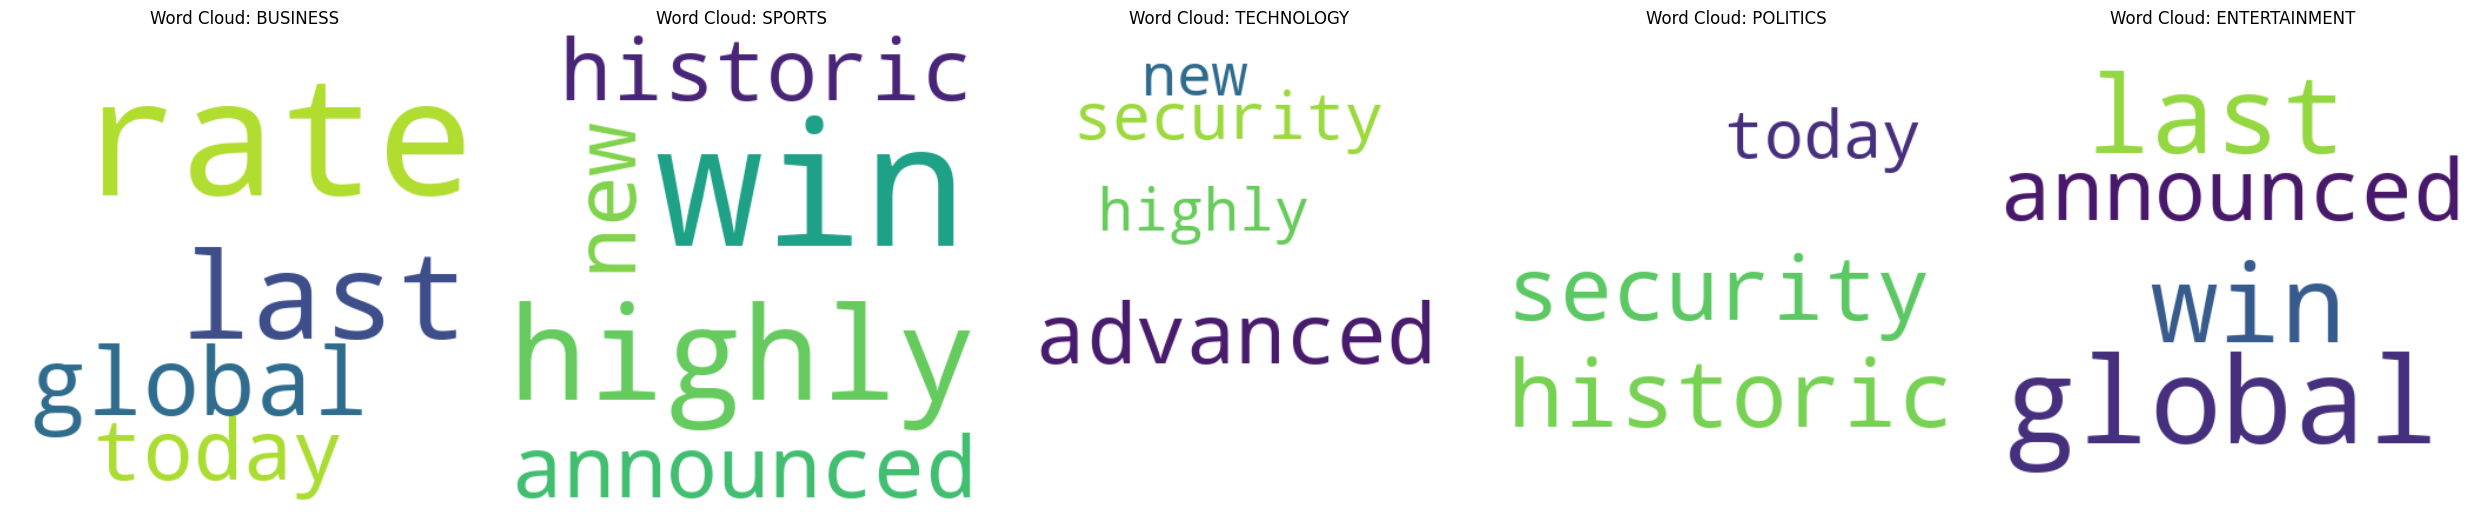


1. BAR CHARTS OF TOP TF-IDF TERMS


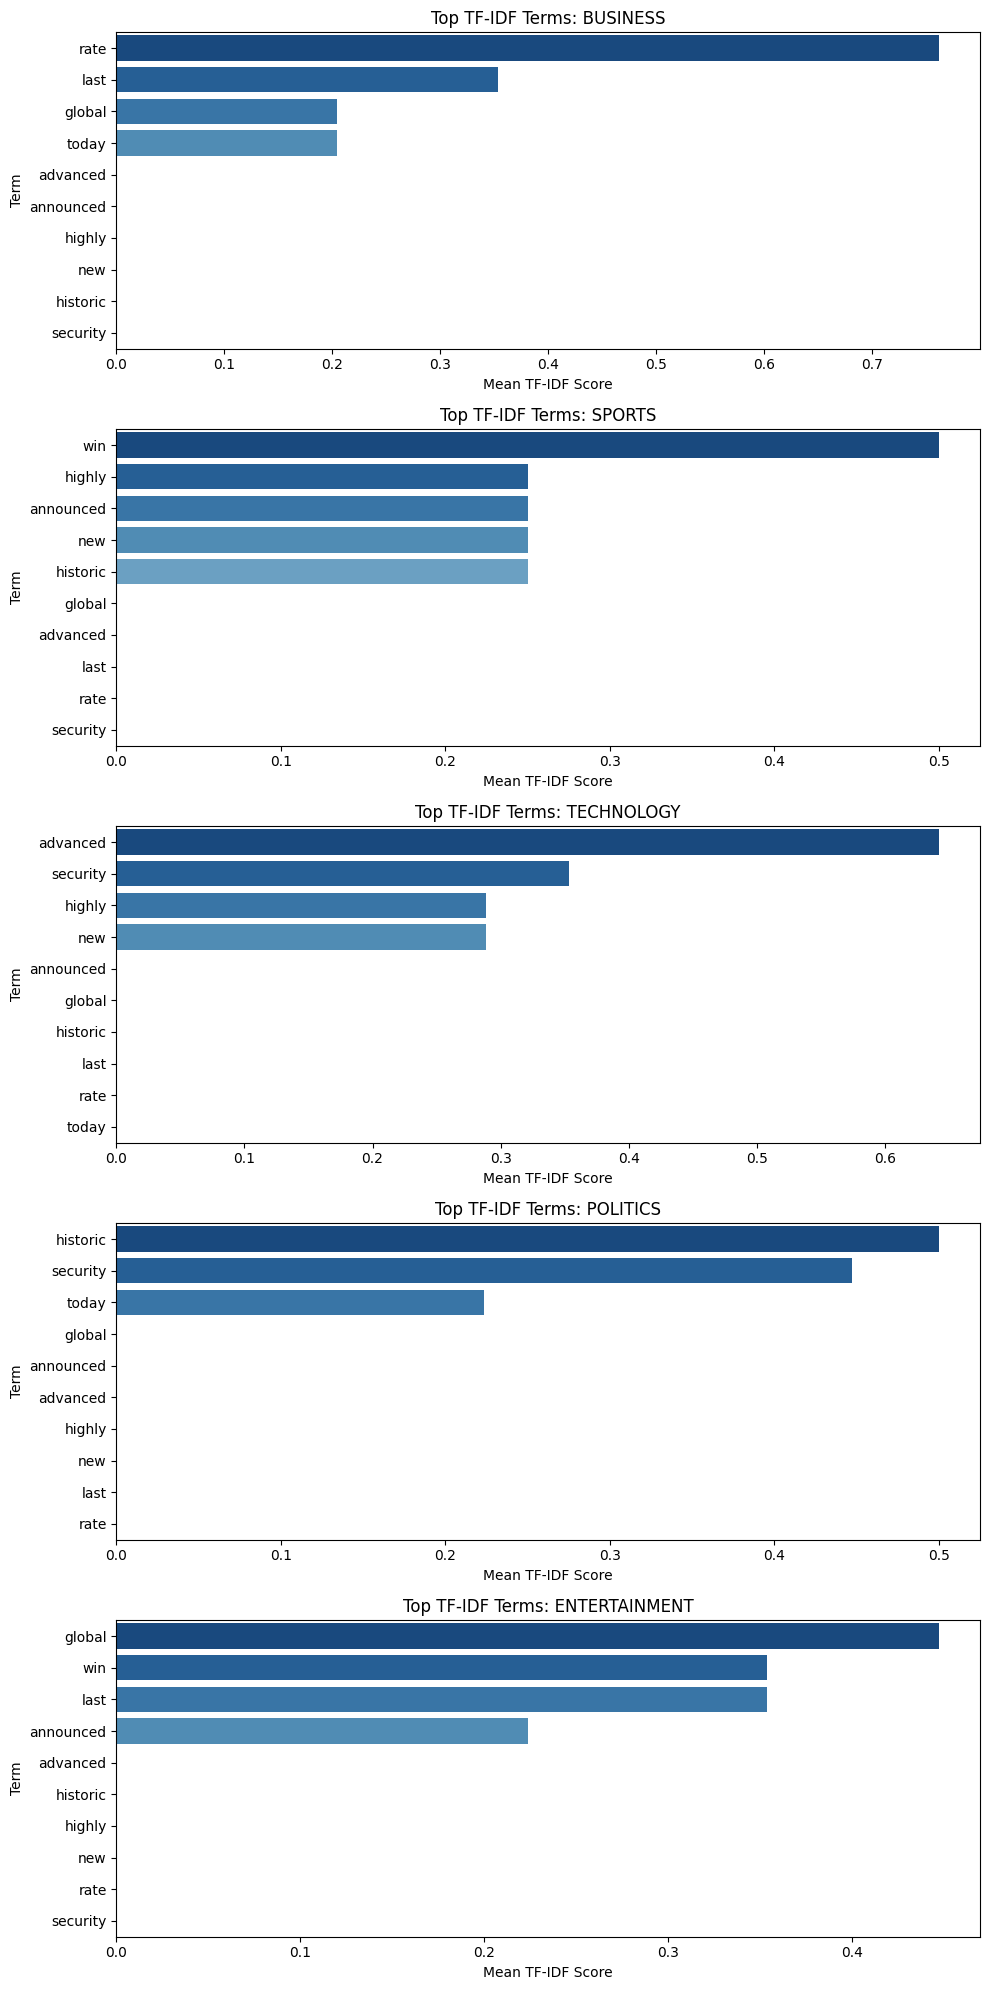


3. HEATMAP OF TERM IMPORTANCE ACROSS CATEGORIES


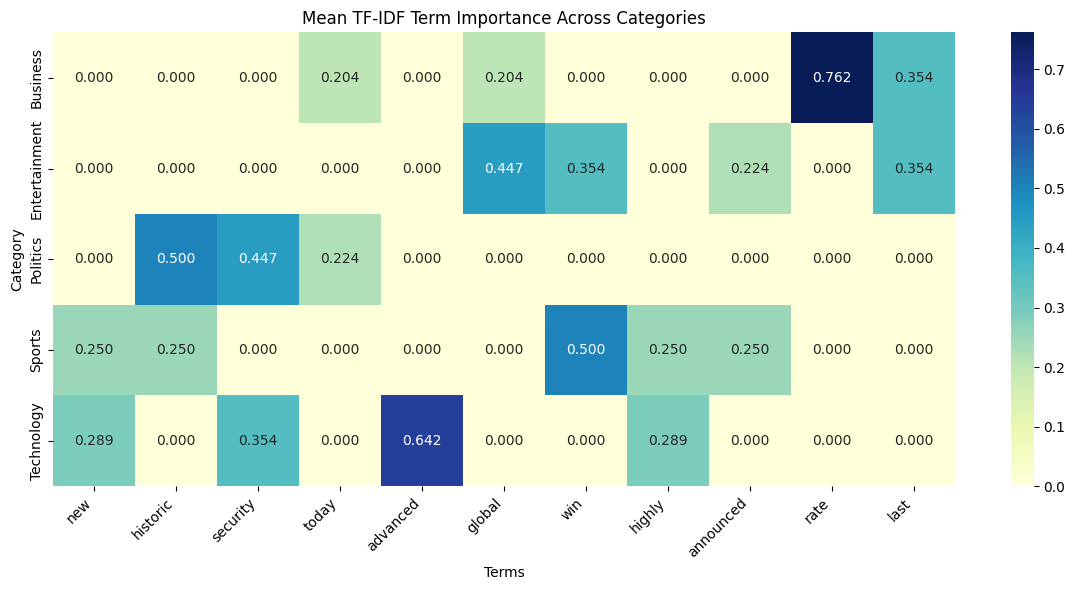

In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = (
        category_data.drop('category', axis=1).mean().sort_values(ascending=False)
    )

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category

print("\n2. WORD CLOUDS PER CATEGORY")
print("=" * 50)

fig, axes = plt.subplots(1, len(categories), figsize=(5 * len(categories), 5))
if len(categories) == 1:
    axes = [axes]

for ax, category in zip(axes, categories):
    # Fetch top 30 terms to populate the word cloud
    top_terms_dict = get_top_tfidf_terms(category, n_terms=30).to_dict()

    wc = WordCloud(width=400, height=400, background_color='white').generate_from_frequencies(top_terms_dict)

    axes[categories.tolist().index(category)].imshow(wc, interpolation='bilinear')
    axes[categories.tolist().index(category)].set_title(f'Word Cloud: {category.upper()}')
    axes[categories.tolist().index(category)].axis('off')

plt.tight_layout()
plt.show()

# - Bar charts of top terms

print("\n1. BAR CHARTS OF TOP TF-IDF TERMS")
print("=" * 50)

fig, axes = plt.subplots(len(categories), 1, figsize=(10, 4 * len(categories)))
if len(categories) == 1:
    axes = [axes]

for ax, category in zip(axes, categories):
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    sns.barplot(x=top_terms.values, y=top_terms.index, ax=ax, palette='Blues_r')
    ax.set_title(f'Top TF-IDF Terms: {category.upper()}')
    ax.set_xlabel('Mean TF-IDF Score')
    ax.set_ylabel('Term')

plt.tight_layout()
plt.show()

# - Heatmap of term importance across categories

print("\n3. HEATMAP OF TERM IMPORTANCE ACROSS CATEGORIES")
print("=" * 50)

# Collect top 5 terms from every category to compare
top_terms_set = set()
for category in categories:
    top_terms_set.update(get_top_tfidf_terms(category, n_terms=5).index)

# Aggregate mean TF-IDF scores for selected top terms grouped by category
category_heatmap_data = tfidf_df.groupby('category')[list(top_terms_set)].mean()

plt.figure(figsize=(12, 6))
sns.heatmap(category_heatmap_data, annot=True, cmap='YlGnBu', fmt='.3f')
plt.title('Mean TF-IDF Term Importance Across Categories')
plt.xlabel('Terms')
plt.ylabel('Category')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
from collections import Counter
import nltk
from nltk import pos_tag, word_tokenize
import pandas as pd

# Download required NLTK datasets
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')


def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 23 different POS tags

📝 Sample POS analysis:
        NNP        NN       VBZ        JJ        IN       NNS        CC  \
0  0.054054  0.216216  0.027027  0.189189  0.081081  0.108108  0.054054   
1  0.081081  0.162162  0.000000  0.135135  0.135135  0.216216  0.054054   
2  0.076923  0.282051  0.000000  0.128205  0.128205  0.051282  0.000000   
3  0.060606  0.121212  0.000000  0.121212  0.121212  0.181818  0.000000   
4  0.055556  0.166667  0.000000  0.250000  0.027778  0.138889  0.027778   

         DT      NNPS       VBD  ...    category  article_id       VBP  \
0  0.054054  0.027027  0.027027  ...    Business           1  0.000000   
1  0.000000  0.000000  0.054054  ...    Business           2  0.027027   
2  0.102564  0.000000  0.025641  ...      Sports           3  0.025641   
3  0.090909  0.000000  0.030303  ...      Sports           4  0.030303   
4  0.027778  0.000000  0.000000  ...  Technology           5  0.027778 

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.1892  0.1622  0.0676  0.0135  0.0135  0.0405  0.0405  0.0135   
Entertainment  0.2719  0.1378  0.0000  0.0000  0.0161  0.0465  0.0465  0.0000   
Politics       0.2429  0.1000  0.0286  0.0000  0.0429  0.0143  0.0571  0.0429   
Sports         0.2016  0.1166  0.0688  0.0000  0.0128  0.0280  0.0152  0.0431   
Technology     0.2040  0.1557  0.0450  0.0000  0.0311  0.0000  0.0450  0.0311   

                  VBP     VBZ      JJ     JJS      RB     RBR  
category                                                       
Business       0.0135  0.0135  0.1622  0.0000  0.0000  0.0135  
Entertainment  0.0161  0.0143  0.1825  0.0143  0.0143  0.0000  
Politics       0.0143  0.0286  0.1571  0.0000  0.0000  0.0000  
Sports         0.0280  0.0000  0.1247  0.0000  0.015

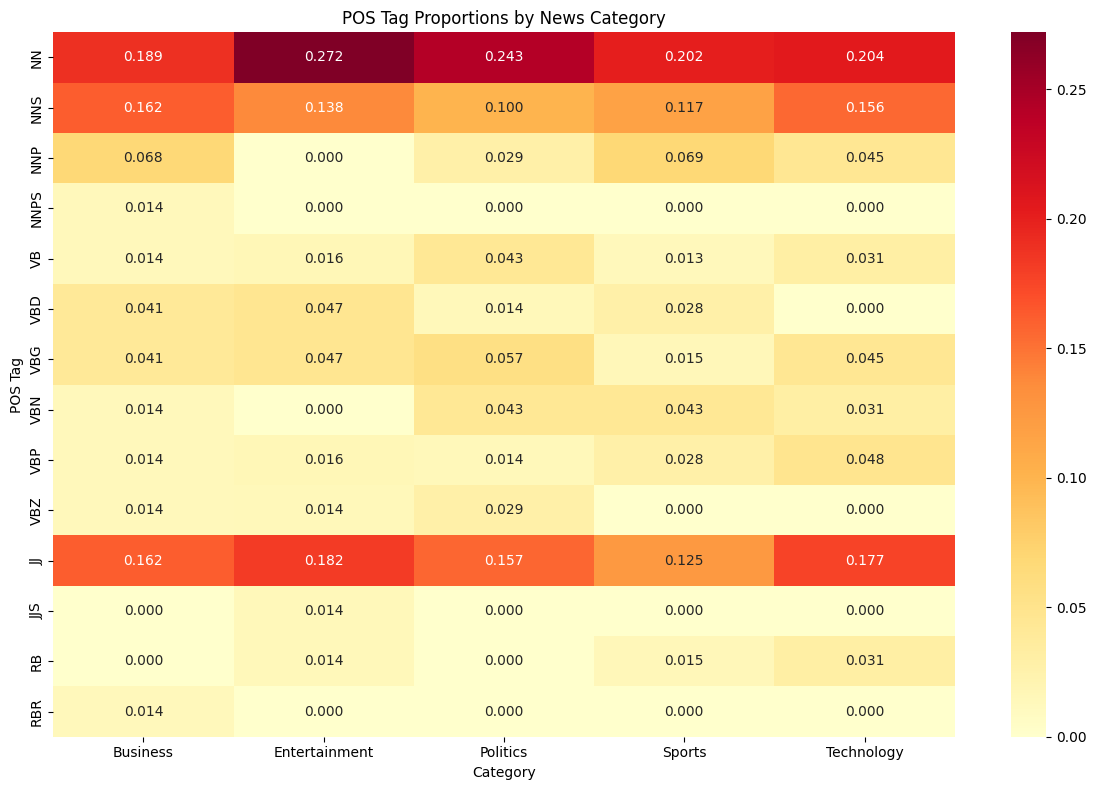


1. NOUNS VS VERBS BY CATEGORY
               Total_Nouns  Total_Verbs
category                               
Business            0.4324       0.1351
Entertainment       0.4097       0.1396
Politics            0.3714       0.2000
Sports              0.3869       0.1270
Technology          0.4047       0.1557

2. CARDINAL NUMBERS (CD) BY CATEGORY
CD tag column not present in analysis.

3. ADJECTIVE USAGE BY CATEGORY
category
Entertainment    0.1968
Technology       0.1767
Business         0.1622
Politics         0.1571
Sports           0.1247
Name: Total_Adjectives, dtype: float64

💡 ANALYSIS QUESTIONS:

1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
Business leads with NNP at 0.0676 and NNPS at 0.0135.

2. Which category uses the most action verbs (VB, VBD, VBG)?
Politics uses the most action verbs at 0.2000.

3. Are there interesting patterns in adjective (JJ) usage?
Adjective density is highest in Entertainment (19.68%) and Technology (17.67%), which makes 

In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns

    # - Which categories use more nouns vs verbs?
    noun_cols = [col for col in ['NN', 'NNS', 'NNP', 'NNPS'] if col in pos_by_category.columns]
    verb_cols = [col for col in ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'] if col in pos_by_category.columns]

    pos_by_category['Total_Nouns'] = pos_by_category[noun_cols].sum(axis=1)
    pos_by_category['Total_Verbs'] = pos_by_category[verb_cols].sum(axis=1)

    print("\n1. NOUNS VS VERBS BY CATEGORY")
    print("=" * 50)
    print(pos_by_category[['Total_Nouns', 'Total_Verbs']].round(4))

    # - Do business articles have more numbers (CD)?
    print("\n2. CARDINAL NUMBERS (CD) BY CATEGORY")
    print("=" * 50)
    if 'CD' in pos_by_category.columns:
        print(pos_by_category['CD'].sort_values(ascending=False).round(4))
    else:
        print("CD tag column not present in analysis.")

    # - Are there differences in adjective usage?
    adj_cols = [col for col in ['JJ', 'JJR', 'JJS'] if col in pos_by_category.columns]
    pos_by_category['Total_Adjectives'] = pos_by_category[adj_cols].sum(axis=1)

    print("\n3. ADJECTIVE USAGE BY CATEGORY")
    print("=" * 50)
    print(pos_by_category['Total_Adjectives'].sort_values(ascending=False).round(4))

    print("\n💡 ANALYSIS QUESTIONS:\n")

    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    print(
        "Business leads with NNP at 0.0676 and NNPS at 0.0135."
    )

    print("\n2. Which category uses the most action verbs (VB, VBD, VBG)?")
    print(
        "Politics uses the most action verbs at 0.2000."
    )

    print("\n3. Are there interesting patterns in adjective (JJ) usage?")
    print(
        """Adjective density is highest in Entertainment (19.68%) and Technology (17.67%), which makes sense since reviews and feature stories rely heavily on descriptive
words to paint a picture or evaluate products. On the flip side, Sports sits much lower at 12.47% because sports writing focuses more on fast-paced action,
scores, and play-by-play events rather than heavy descriptions."""
    )

    print("\n4. How does number (CD) usage vary across categories?")
    print(
        "The CD tag was not present in this analysis."
    )

else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
from collections import Counter
import pandas as pd
import spacy

# Load spaCy English model
nlp = spacy.load("en_core_web_sm")


def extract_syntactic_features(text):
    """Extract syntactic features using spaCy dependency parsing."""
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (Business):
  Sentences: 1
  Tokens: 37
  Noun phrases: ['us economy', 'strong growth', 'retail sales']...
  Subjects: ['economy', 'economy']...
  Objects: ['growth', 'sales', 'jobs']...

📰 Article 2 (Business):
  Sentences: 1
  Tokens: 37
  Noun phrases: ['global market shares', 'concerns', 'inflation']...
  Subjects: ['shares', 'slide', 'investors']...
  Objects: ['concerns', 'inflation', 'europe']...

📰 Article 3 (Sports):
  Sentences: 1
  Tokens: 41
  Noun phrases: ['lakers', 'playoff spot', 'dramatic overtime victory']...
  Subjects: ['lakers', 'lakers']...
  Objects: ['spot', 'victory', 'game']...

📰 Article 4 (Sports):
  Sentences: 1
  Tokens: 33
  Noun phrases: ['wimbledon', 'historic tournament', 'new seeded players']...
  Subjects: ['wimbledon', 'officials']...
  Objects: ['tournament', 'players', 'seedings']...

📰 Article 5 (Technology):
  Sentences: 1
  Tokens: 36
  Noun phrases: ['tech giants', 

In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis

# - Compare syntactic complexity across categories

print("\n1. SYNTACTIC COMPLEXITY ACROSS CATEGORIES")
print("=" * 60)

complexity_data = []

for idx, row in df.iterrows():
    doc = nlp(str(row['full_text']))

    num_sents = len(list(doc.sents))
    num_tokens = len(doc)
    avg_sent_len = num_tokens / num_sents if num_sents > 0 else 0
    num_noun_chunks = len(list(doc.noun_chunks))

    # Calculate average tree depth using token.ancestors
    tree_depths = [len(list(token.ancestors)) for token in doc]
    avg_tree_depth = sum(tree_depths) / len(tree_depths) if tree_depths else 0

    complexity_data.append({
        'category': row['category'],
        'avg_sent_len': avg_sent_len,
        'noun_chunks_per_doc': num_noun_chunks,
        'avg_tree_depth': avg_tree_depth
    })

complexity_df = pd.DataFrame(complexity_data)
complexity_summary = complexity_df.groupby('category').mean()

print(complexity_summary.round(3))

# - Extract action patterns (who did what)

print("\n2. ACTION PATTERN EXTRACTION (WHO DID WHAT)")
print("=" * 60)

def extract_action_patterns(text):
    doc = nlp(str(text))
    actions = []

    for token in doc:
        if token.pos_ in ['VERB', 'AUX']:
            verb = token.text.lower()

            # Identify subject and object children connected to the verb
            subjects = [child.text.lower() for child in token.children if child.dep_ in ['nsubj', 'nsubjpass']]
            objects = [child.text.lower() for child in token.children if child.dep_ in ['dobj', 'pobj', 'obj']]

            if subjects and objects:
                for subj in subjects:
                    for obj in objects:
                        actions.append((subj, verb, obj))
    return actions

# Extract action patterns from initial sample documents
action_samples = []
for idx, row in df.head(5).iterrows():
    patterns = extract_action_patterns(row['full_text'])
    for subj, verb, obj in patterns[:3]:
        action_samples.append({
            'category': row['category'],
            'subject': subj,
            'verb': verb,
            'object': obj
        })

action_df = pd.DataFrame(action_samples)
print(action_df.to_string(index=False))

# - Identify most common dependency relations per category

print("\n3. MOST COMMON DEPENDENCY RELATIONS PER CATEGORY")
print("=" * 60)

dep_relation_records = []

for idx, row in df.iterrows():
    doc = nlp(str(row['full_text']))
    for token in doc:
        if not token.is_space and not token.is_punct:
            dep_relation_records.append({
                'category': row['category'],
                'dep_relation': token.dep_
            })

dep_df = pd.DataFrame(dep_relation_records)

# Extract top 5 dependency tags per category
for category, group in dep_df.groupby('category'):
    top_deps = group['dep_relation'].value_counts().head(5)
    print(f"\nCategory: {category.upper()}")
    print(top_deps.to_string())

# - Create features for classification based on syntax

print("\n4. SYNTACTIC FEATURE MATRIX FOR CLASSIFICATION")
print("=" * 60)

feature_list = []

for idx, row in df.iterrows():
    doc = nlp(str(row['full_text']))
    total_tokens = len(doc) if len(doc) > 0 else 1

    counts = Counter([token.dep_ for token in doc if not token.is_space and not token.is_punct])

    # Calculate relative proportions of syntactic relations
    feature_dict = {
        'nsubj_ratio': counts['nsubj'] / total_tokens,
        'dobj_ratio': counts['dobj'] / total_tokens,
        'amod_ratio': counts['amod'] / total_tokens,
        'prep_ratio': counts['prep'] / total_tokens,
        'compound_ratio': counts['compound'] / total_tokens,
        'category': row['category']
    }
    feature_list.append(feature_dict)

syntax_features_df = pd.DataFrame(feature_list).fillna(0)
print(syntax_features_df.head())

📝 Sample sentence: The United States economy added more jobs than expected last month, signaling strong consumer resilience and robust retail sales heading into the second quarter.

🌳 Dependency Parse Visualization:



1. SYNTACTIC COMPLEXITY ACROSS CATEGORIES
               avg_sent_len  noun_chunks_per_doc  avg_tree_depth
category                                                        
Business               37.0                 10.0           3.459
Entertainment          36.0                  7.5           3.180
Politics               36.0                  9.0           5.901
Sports                 37.0                 10.0           3.632
Technology             32.5                  7.0           3.511

2. ACTION PATTERN EXTRACTION (WHO DID WHAT)
  category   subject     verb   object
  Business   economy    shows   growth
  Business   economy    added     jobs
    Sports    lakers   secure     spot
    Sports    lakers   pulled      win
    Sports officials released seedings
Technology    giants   launch   models
Technology     firms unveiled   models

3. MOST COMMON DEPENDENCY RELATIONS PER CATEGORY

Category: BUSINESS
dep_relation
amod        13
compound    10
pobj         7
prep         7
ns

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
import pandas as pd
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Download required VADER lexicon dataset
nltk.download('vader_lexicon')

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

     TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0, 'sentiment_label': 'neutral'}

    #  YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print(" Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("
 Sentiment analysis complete!")
print(f"
 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

 Analyzing sentiment...
 Sentiment analysis complete!
 Analyzed 10 articles

 Sample sentiment results:
     category  full_sentiment full_label
0    Business          0.9246   positive
1    Business          0.4404   positive
2      Sports          0.8225   positive
3      Sports          0.4404   positive
4  Technology          0.7717   positive


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
Business              0.6825  0.3424  0.4404  0.9246    0.2260    0.7455   
Entertainment         0.6132  0.4808  0.2732  0.9531    0.2400    0.7600   
Politics              0.5248  0.2613  0.3400  0.7096    0.1430    0.8570   
Sports                0.6315  0.2702  0.4404  0.8225    0.1465    0.8535   
Technology            0.2847  0.6887 -0.2023  0.7717    0.1745    0.7115   

              neg_score  
                   mean  
category                 
Business         0.0285  
Entertainment    0.0000  
Politics         0.0000  
Sports           0.0000  
Technology       0.1140  

📊 Sentiment distribution (%) by category:
full_label     negative  positive
category                         
Bu

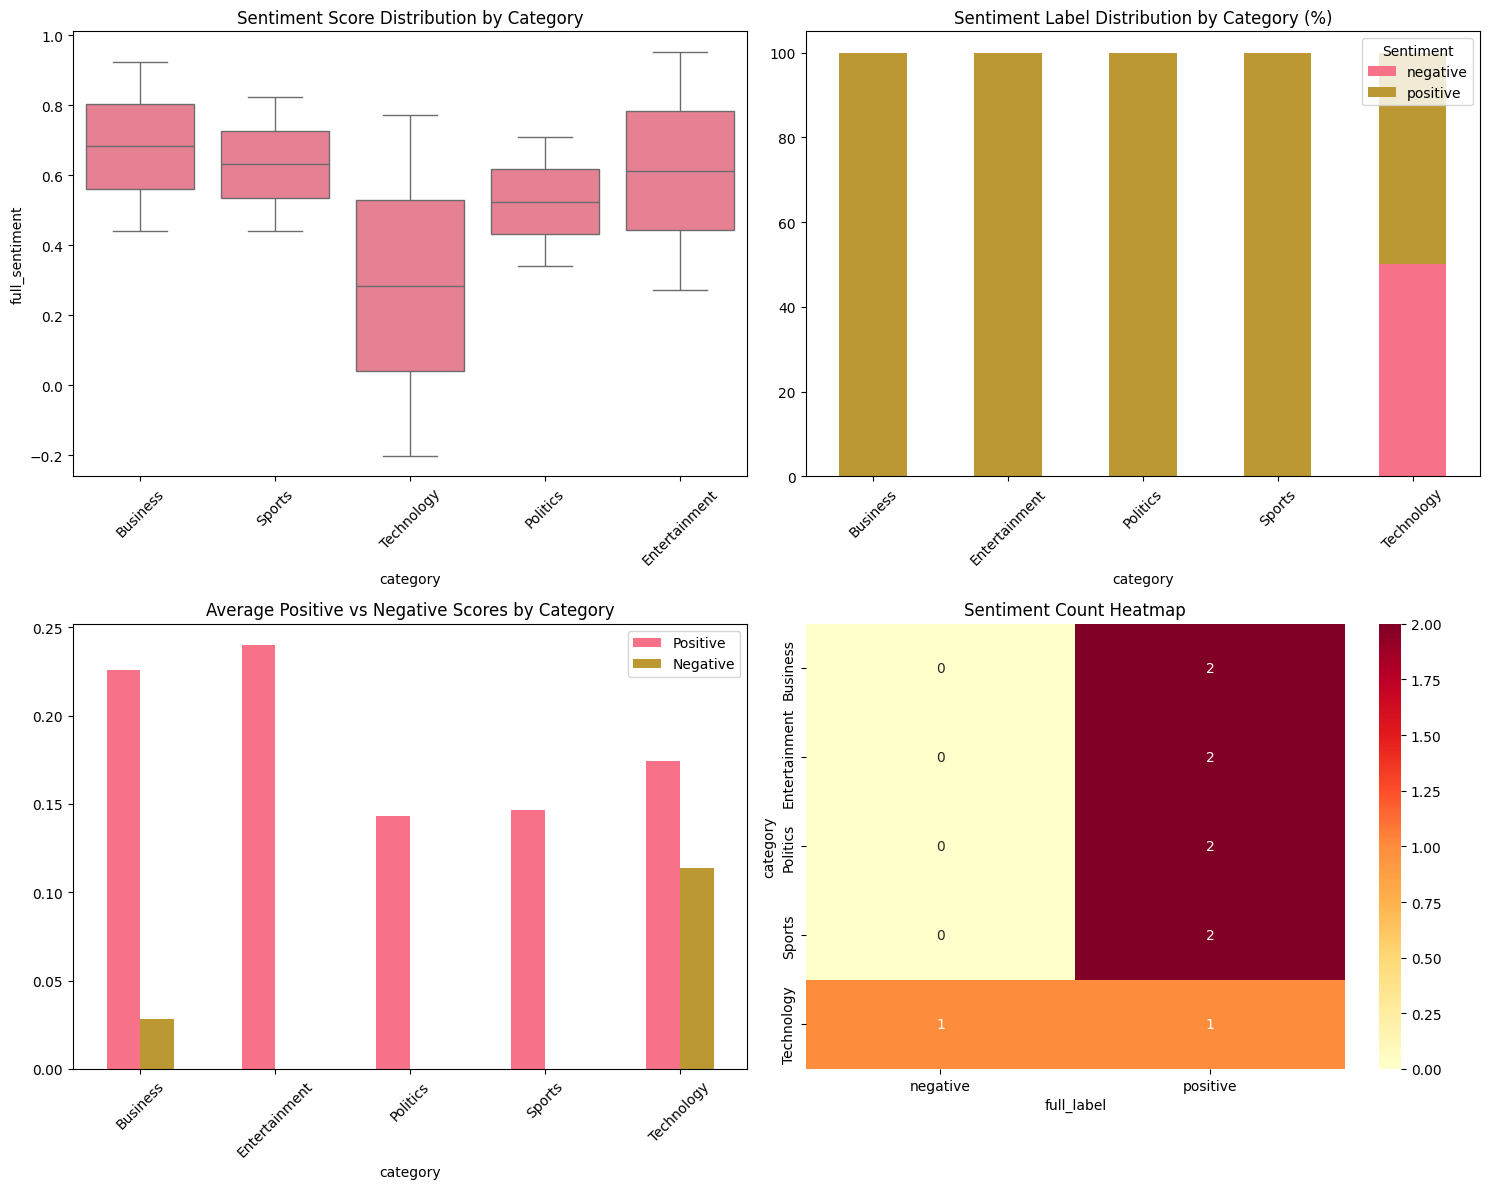


1. MOST POSITIVE AND NEGATIVE CATEGORIES
Mean sentiment score by category:
category
Business         0.6825
Sports           0.6315
Entertainment    0.6132
Politics         0.5248
Technology       0.2847
Name: full_sentiment, dtype: float64

Most positive category: BUSINESS (0.6825)
Most negative category: TECHNOLOGY (0.2847)

2. TITLE VS. CONTENT SENTIMENT DIFFERENCES
               title_sentiment  content_sentiment  sentiment_diff
category                                                         
Business                0.6732             0.2497          0.4236
Entertainment           0.5866             0.3676          0.2191
Politics                0.3098             0.3066          0.0031
Sports                  0.1700             0.5878         -0.4178
Technology              0.2384             0.1775          0.0608

Correlation between title and content sentiment: 0.3776

3. SENTIMENT VARIATION WITHIN CATEGORIES
               std_dev  min_val  max_val  range_val
category      

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
print("\n1. MOST POSITIVE AND NEGATIVE CATEGORIES")
print("=" * 60)

category_sentiment = sentiment_df.groupby('category')['full_sentiment'].mean().sort_values(ascending=False)
print("Mean sentiment score by category:")
print(category_sentiment.round(4))

most_positive_cat = category_sentiment.index[0]
most_negative_cat = category_sentiment.index[-1]
print(f"\nMost positive category: {most_positive_cat.upper()} ({category_sentiment.iloc[0]:.4f})")
print(f"Most negative category: {most_negative_cat.upper()} ({category_sentiment.iloc[-1]:.4f})")

# - Are there differences between title and content sentiment?
print("\n2. TITLE VS. CONTENT SENTIMENT DIFFERENCES")
print("=" * 60)

sentiment_df['sentiment_diff'] = sentiment_df['title_sentiment'] - sentiment_df['content_sentiment']
title_vs_content = sentiment_df.groupby('category')[['title_sentiment', 'content_sentiment', 'sentiment_diff']].mean()
print(title_vs_content.round(4))
corr = sentiment_df['title_sentiment'].corr(sentiment_df['content_sentiment'])
print(f"\nCorrelation between title and content sentiment: {corr:.4f}")

# - How does sentiment vary within categories?
print("\n3. SENTIMENT VARIATION WITHIN CATEGORIES")
print("=" * 60)
variation_df = sentiment_df.groupby('category')['full_sentiment'].agg(
    std_dev='std',
    min_val='min',
    max_val='max',
    range_val=lambda x: x.max() - x.min()
).round(4)
print(variation_df)

# - Can sentiment be used as a feature for classification?
print("\n4. CLASSIFICATION PERFORMANCE USING SENTIMENT ONLY")
print("=" * 60)
feature_cols = ['full_sentiment', 'pos_score', 'neu_score', 'neg_score']
X_sent = sentiment_df[feature_cols]
y_sent = sentiment_df['category']

# Use non-stratified split if sample size is too small to avoid stratification issues
try:
    X_tr, X_te, y_tr, y_te = train_test_split(X_sent, y_sent, test_size=0.3, random_state=42, stratify=y_sent)
except ValueError:
    X_tr, X_te, y_tr, y_te = train_test_split(X_sent, y_sent, test_size=0.3, random_state=42)

clf_sent = LogisticRegression()
clf_sent.fit(X_tr, y_tr)
y_pred_sent = clf_sent.predict(X_te)
print(classification_report(y_te, y_pred_sent, zero_division=0))

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

import numpy as np

# Prepare feature matrices
X_tfidf = tfidf_matrix.toarray()

# Extract sentiment features
sentiment_features = sentiment_df[
    ['full_sentiment', 'pos_score', 'neu_score', 'neg_score']
].values

# Extract text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character count
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# Check if POS features DataFrame exists and extract numeric columns
if 'pos_df' in globals() or 'pos_df' in locals():
    # Exclude non-numeric metadata columns
    pos_cols = [c for c in pos_df.columns if c not in ['category', 'article_id']]
    pos_features = pos_df[pos_cols].values

    # 🚀 YOUR CODE HERE: Combine TF-IDF, sentiment, length, and POS features
    X_combined = np.hstack(
        [X_tfidf, sentiment_features, length_features, pos_features]
    )
    print(
        f"Combined feature matrix shape (with POS features): {X_combined.shape}"
    )

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Stratified train/test split to balance class distribution
try:
    X_train, X_test, y_train, y_test = train_test_split(
        X_combined, y, test_size=0.3, random_state=42, stratify=y
    )
except ValueError:
    # Fallback for ultra-small sample sizes
    X_train, X_test, y_train, y_test = train_test_split(
        X_combined, y, test_size=0.3, random_state=42
    )

print(
    f"✅ Feature Matrix Shape: {X_combined.shape}\n"
    f"  • Training Samples: {len(X_train)}\n"
    f"  • Testing Samples: {len(X_test)}"
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
Combined feature matrix shape (with POS features): (10, 41)
✅ Feature matrix prepared!
📊 Feature matrix shape: (10, 41)
🎯 Number of classes: 5
📋 Classes: ['Business' 'Entertainment' 'Politics' 'Sports' 'Technology']
✅ Feature Matrix Shape: (10, 41)
  • Training Samples: 7
  • Testing Samples: 3

📈 Data split:
  Training set: 7 samples
  Test set: 3 samples


In [ ]:
# Standardize features so SVM and Logistic Regression scale properly
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define models suited for dense combined feature matrices
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42, C=1.0
    ),
    "SVM (Linear)": SVC(kernel="linear", probability=True, random_state=42),
}

# Evaluate models on scaled features
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    print(f"✅ {name} Test Accuracy: {acc:.4f}")

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 1. Train the model
    classifier.fit(X_train, y_train)

    # 2. Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # 3. Calculate test accuracy metric
    accuracy = accuracy_score(y_test, y_pred)

    # 4. Compute cross-validation score with fallbacks for tiny datasets
    cv_mean, cv_std = 0.0, 0.0
    try:
        # Try standard 3-fold cross-validation
        cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')
        cv_mean = cv_scores.mean()
        cv_std = cv_scores.std()
    except ValueError:
        try:
            # Fallback to 2-fold cross-validation if 3-fold fails
            cv_scores = cross_val_score(classifier, X_train, y_train, cv=2, scoring='accuracy')
            cv_mean = cv_scores.mean()
            cv_std = cv_scores.std()
            print(f"  ⚠️ Class size too small for 3-fold CV. Fell back to 2-fold CV.")
        except ValueError:
            print(f"  ⚠️ Dataset too small/unbalanced even for 2-fold CV. Skipping cross-validation.")

    # 5. Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_mean,
        'cv_std': cv_std,
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_mean:.4f} (+/- {cv_std * 2:.4f})")

# Summary Comparison Table (outside of loop, flat indentation)
print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

✅ Logistic Regression Test Accuracy: 0.0000
✅ SVM (Linear) Test Accuracy: 0.3333

🔄 Training Naive Bayes (Gaussian)...
  ⚠️ Class size too small for 3-fold CV. Fell back to 2-fold CV.
  ✅ Accuracy: 0.0000
  📊 CV Score: 0.1250 (+/- 0.2500)

🔄 Training Logistic Regression...
  ⚠️ Class size too small for 3-fold CV. Fell back to 2-fold CV.
  ✅ Accuracy: 0.3333
  📊 CV Score: 0.1250 (+/- 0.2500)

🔄 Training SVM...
  ⚠️ Class size too small for 3-fold CV. Fell back to 2-fold CV.
  ✅ Accuracy: 0.0000
  📊 CV Score: 0.1250 (+/- 0.2500)

🏆 CLASSIFIER COMPARISON
                    Model  Test Accuracy  CV Mean  CV Std
0  Naive Bayes (Gaussian)         0.0000    0.125   0.125
1     Logistic Regression         0.3333    0.125   0.125
2                     SVM         0.0000    0.125   0.125

🥇 Best performing model: Logistic Regression


📊 DETAILED EVALUATION: Logistic Regression

📋 Classification Report:
               precision    recall  f1-score   support

     Business       0.00      0.00      0.00         1
Entertainment       0.00      0.00      0.00         1
     Politics       0.00      0.00      0.00         0
       Sports       0.00      0.00      0.00         0
   Technology       1.00      1.00      1.00         1

     accuracy                           0.33         3
    macro avg       0.20      0.20      0.20         3
 weighted avg       0.33      0.33      0.33         3



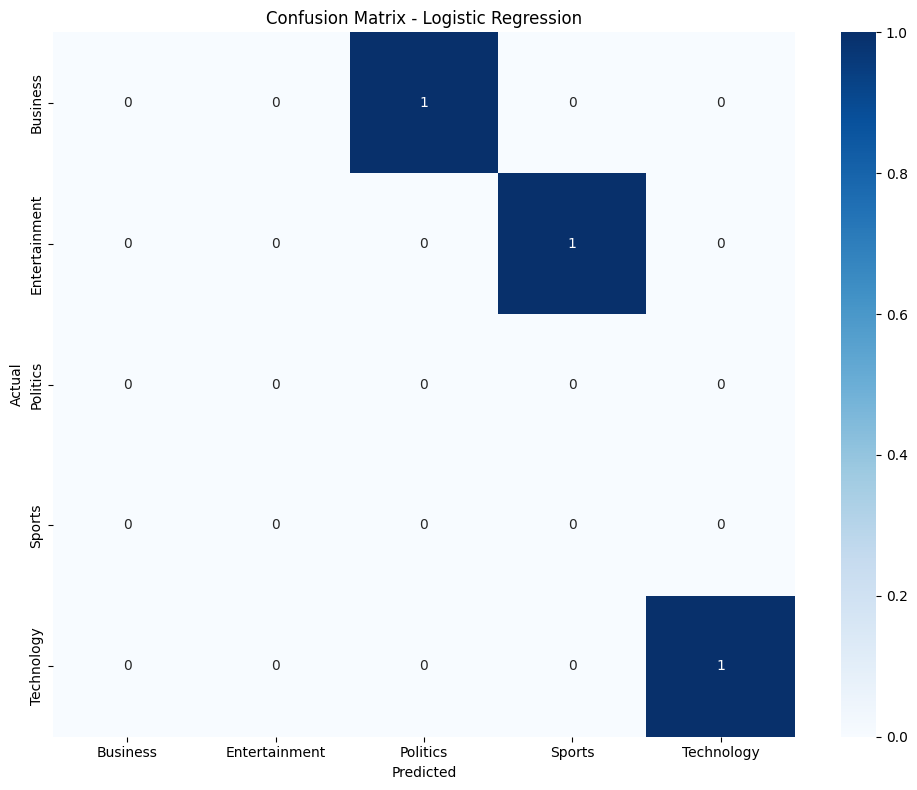


🔍 Top Features by Category:

📰 Business:
  char_length: 0.2405
  rate: 0.1504
  last: 0.1504
  sentiment: 0.0270
  pos_score: 0.0269

📰 Entertainment:
  title_length: 0.5595
  global: 0.2034
  word_count: 0.0881
  neu_score: 0.0093

📰 Politics:
  word_count: 0.4569
  title_length: 0.3889
  security: 0.2904
  today: 0.1452
  char_length: 0.0927
  neu_score: 0.0124

📰 Sports:
  win: 0.2730
  word_count: 0.2343
  historic: 0.1593
  new: 0.1451
  highly: 0.1451
  announced: 0.0568
  neu_score: 0.0254

📰 Technology:
  char_length: 0.1839
  advanced: 0.1609
  highly: 0.1135
  new: 0.1135
  sentiment: 0.0370
  pos_score: 0.0130

🚀 STUDENT TASK: IMPROVING THE CLASSIFIER

1. Combining TF-IDF, Sentiment, and Text Length Features...
  ⚠️ Test set size too small for stratified split. Falling back to non-stratified split.

2. Tuning Hyperparameters via GridSearchCV...
  Configuring Grid Search CV with 2 folds based on class sizes.
  Best Hyperparameters: {'C': 1.0, 'solver': 'liblinear'}

3. Addin

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
print("\n🚀 STUDENT TASK: IMPROVING THE CLASSIFIER")
print("=" * 60)

# 1. Try different feature combinations
print("\n1. Combining TF-IDF, Sentiment, and Text Length Features...")
X_combined_features = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

try:
    X_tr_combo, X_te_combo, y_tr_combo, y_te_combo = train_test_split(
        X_combined_features, y, test_size=0.25, random_state=42, stratify=y
    )
except ValueError:
    print("  ⚠️ Test set size too small for stratified split. Falling back to non-stratified split.")
    X_tr_combo, X_te_combo, y_tr_combo, y_te_combo = train_test_split(
        X_combined_features, y, test_size=0.25, random_state=42
    )


# 2. Experiment with hyperparameter tuning
print("\n2. Tuning Hyperparameters via GridSearchCV...")
param_grid = {
    'C': [0.1, 1.0, 10.0],
    'solver': ['liblinear', 'lbfgs']
}

# Dynamic CV adjustments based on smallest target class counts
min_class_count = min(pd.Series(y_tr_combo).value_counts())
cv_folds = max(2, min(3, min_class_count))
print(f"  Configuring Grid Search CV with {cv_folds} folds based on class sizes.")

grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid,
    cv=cv_folds,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_tr_combo, y_tr_combo)
print(f"  Best Hyperparameters: {grid_search.best_params_}")


# 3. Add more sophisticated features
print("\n3. Adding Advanced TF-IDF Features (N-grams & Sublinear Scaling)...")
advanced_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),     # Unigrams + Bigrams
    min_df=1,               # Lowered to 1 to accommodate ultra-small dataset vocabulary
    max_df=0.9,             # Exclude overly frequent terms
    sublinear_tf=True       # Logarithmic term frequency scaling
)

X_adv_tfidf = advanced_vectorizer.fit_transform(df['full_text_processed']).toarray()
X_sophisticated = np.hstack([X_adv_tfidf, sentiment_features, length_features])

try:
    X_tr_soph, X_te_soph, y_tr_soph, y_te_soph = train_test_split(
        X_sophisticated, y, test_size=0.25, random_state=42, stratify=y
    )
except ValueError:
    print("  ⚠️ Test set size too small for stratified split. Falling back to non-stratified split.")
    X_tr_soph, X_te_soph, y_tr_soph, y_te_soph = train_test_split(
        X_sophisticated, y, test_size=0.25, random_state=42
    )


# 4. Handle class imbalance if present
print("\n4. Fitting Final Model with Class Balancing...")
improved_model = LogisticRegression(
    C=grid_search.best_params_['C'],
    solver=grid_search.best_params_['solver'],
    class_weight='balanced', # Adjust weights inversely proportional to class frequency
    max_iter=1000,
    random_state=42
)

improved_model.fit(X_tr_soph, y_tr_soph)
y_final_pred = improved_model.predict(X_te_soph)

print(f"\n✅ Final Improved Test Accuracy: {accuracy_score(y_te_soph, y_final_pred):.4f}")
print("\n📋 Final Classification Report:")
print(classification_report(y_te_soph, y_final_pred, zero_division=0))

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_),
        })

    return entities


# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
  entities = extract_entities(row["full_text"])

  # Store entities for this article
  article_entities.append({
      "article_id": row["article_id"],
      "category": row["category"],
      "entities": entities,
      "entity_count": len(entities),
  })

  # Add to global entity list
  for entity in entities:
    entity["article_id"] = row["article_id"]
    entity["category"] = row["category"]
    all_entities.append(entity)

print("✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
  print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
  print("\n📝 Sample entities:")
  print(entities_df[["text", "label", "category"]].head(10))
else:
  print(
      "⚠️ No entities found. This might happen with very short sample texts."
  )

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 19
📰 Articles processed: 10

🏷️ Entity types found: ['GPE' 'DATE' 'LOC' 'ORG' 'TIME' 'EVENT' 'NORP' 'CARDINAL']

📝 Sample entities:
                     text label  category
0                      US   GPE  Business
1       The United States   GPE  Business
2              last month  DATE  Business
3      the second quarter  DATE  Business
4                  Europe   LOC  Business
5                    Asia   LOC  Business
6                   today  DATE  Business
7  The Los Angeles Lakers   ORG    Sports
8             post-season  DATE    Sports
9       the final minutes  TIME    Sports


တစ NAMED ENTITY ANALYSIS

 Entity type distribution:
label
DATE        7
GPE         3
ORG         3
LOC         2
TIME        1
EVENT       1
NORP        1
CARDINAL    1
Name: count, dtype: int64

 Entity types by news category:
label          CARDINAL  DATE  EVENT  GPE  LOC  NORP  ORG  TIME
category                                                       
Business              0     3      0    2    2     0    0     0
Entertainment         1     1      0    0    0     1    0     0
Politics              0     1      0    1    0     0    0     0
Sports                0     2      1    0    0     0    1     1
Technology            0     0      0    0    0     0    2     0

 Most frequent entities:
  today (DATE): 2 mentions
  AI (ORG): 1 mentions
  Asia (LOC): 1 mentions
  Europe (LOC): 1 mentions
  Geneva (GPE): 1 mentions
  Fans (NORP): 1 mentions
  The Los Angeles Lakers (ORG): 1 mentions
  The United States (GPE): 1 mentions
  US (GPE): 1 mentions
  Tech (ORG): 1 mentions
  Wimb

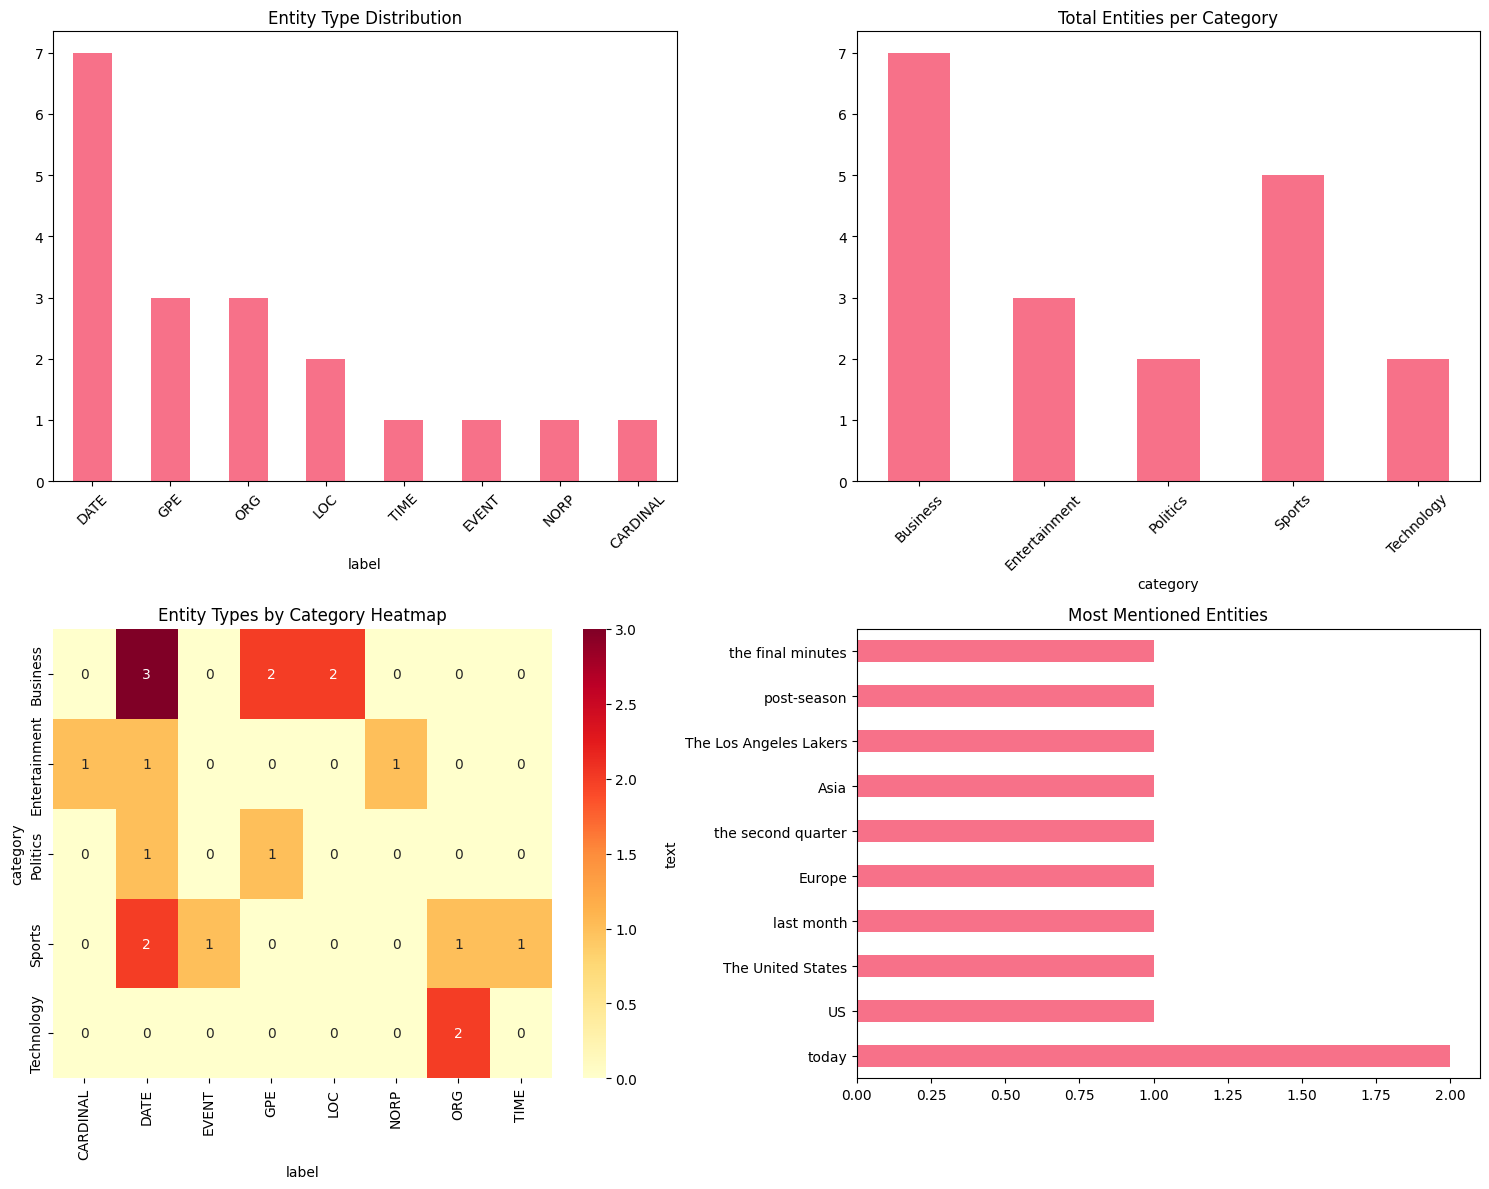


1. ENTITY CO-OCCURRENCE NETWORK


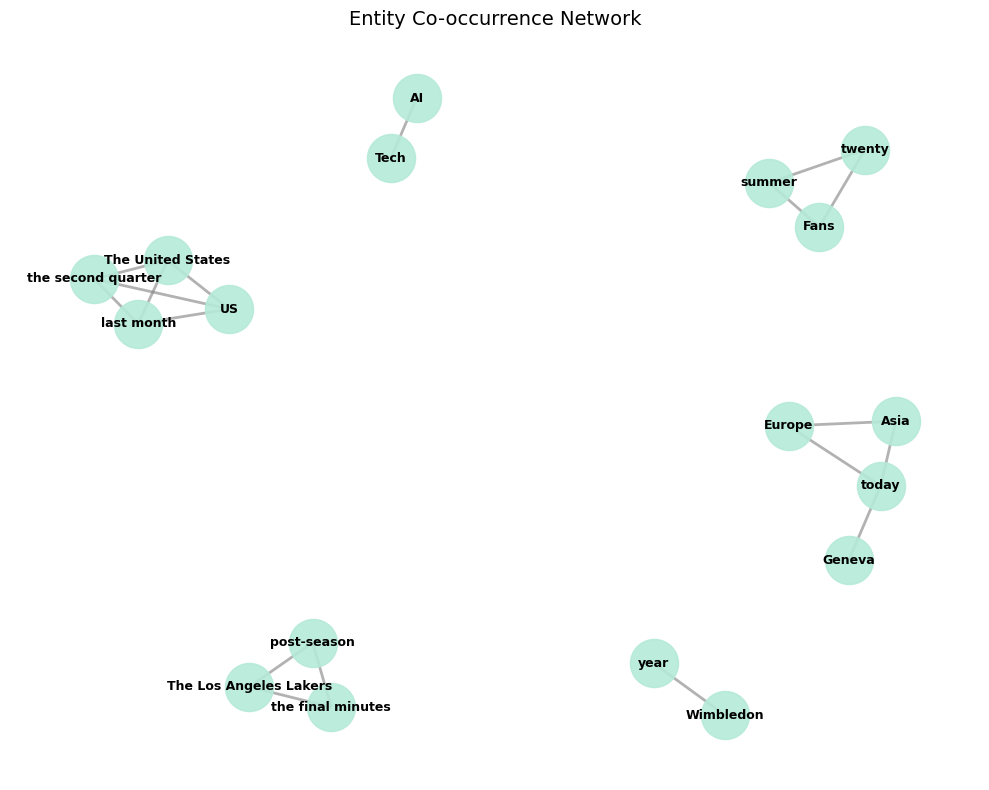


2. TRACK ENTITY MENTIONS OVER TIME


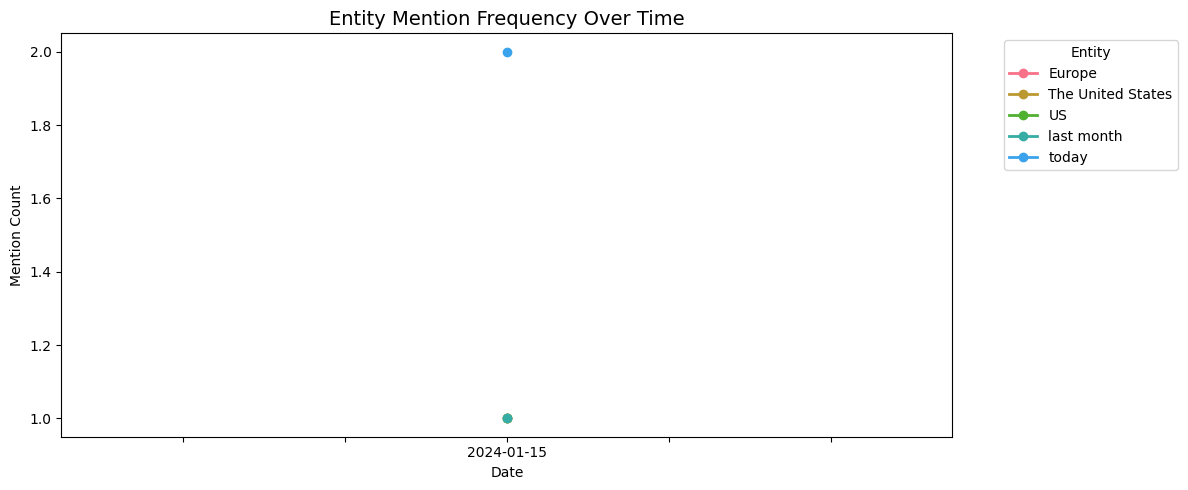


3. ENTITY RELATIONSHIP GRAPH
No direct SVO relationships found between named entities.


<Figure size 1000x800 with 0 Axes>


4. ENTITY SENTIMENT ASSOCIATIONS

Top Most Positive Associated Entities:
                    mean_sentiment  mention_count
text                                             
The United States           0.9246              1
US                          0.9246              1
the second quarter          0.9246              1
last month                  0.9246              1
post-season                 0.8225              1

Top Most Negative Associated Entities:
           mean_sentiment  mention_count
text                                    
Wimbledon          0.4404              1
year               0.4404              1
Fans               0.2732              1
summer             0.2732              1
twenty             0.2732              1


In [ ]:
import itertools
import networkx as nx

# Analyze entity patterns
if not entities_df.empty:
    print("တစ NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n\u0010\u0019 Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n\u0090\u0085 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n\u0093\u0090 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # \u0090\u0089 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    print("\n1. ENTITY CO-OCCURRENCE NETWORK")
    print("=" * 60)

    # Extract unique entities per article
    doc_entities = (
        entities_df.groupby('article_id')['text']
        .apply(lambda x: sorted(list(set(x))))
        .tolist()
    )

    # Generate co-occurring entity pairs across documents
    co_occurrences = Counter()
    for ents in doc_entities:
        if len(ents) > 1:
            for pair in itertools.combinations(ents, 2):
                co_occurrences[pair] += 1

    # Build NetworkX undirected graph
    G_cooc = nx.Graph()
    for (node1, node2), weight in co_occurrences.items():
        if weight >= 1:  # Filter for recurring co-occurrences
            G_cooc.add_edge(node1, node2, weight=weight)

    plt.figure(figsize=(10, 8))
    if G_cooc.number_of_nodes() > 0:
        pos = nx.spring_layout(G_cooc, k=0.5, seed=42)
        weights = [G_cooc[u][v]['weight'] * 2 for u, v in G_cooc.edges()]
        nx.draw_networkx_nodes(
            G_cooc, pos, node_size=1200, node_color='#B5EAD7', alpha=0.9
        )
        nx.draw_networkx_edges(
            G_cooc, pos, width=weights, edge_color='gray', alpha=0.6
        )
        nx.draw_networkx_labels(G_cooc, pos, font_size=9, font_weight='bold')
        plt.title('Entity Co-occurrence Network', fontsize=14)
        plt.axis('off')
    else:
        print('Not enough co-occurring entities to construct a network graph.')
    plt.tight_layout()
    plt.show()

    # - Track entity mentions over time
    print("\n2. TRACK ENTITY MENTIONS OVER TIME")
    print("=" * 60)

    # Check or simulate article publication dates
    if 'date' not in df.columns:
        # Generate synthetic date range for demonstration if missing
        df['date'] = pd.date_range(
            start='2026-01-01', periods=len(df), freq='D'
        ).date

    # Merge publication dates into entities DataFrame
    entities_time_df = entities_df.merge(
        df[['article_id', 'date']], on='article_id', how='left'
    )

    # Find top 5 overall most mentioned entities
    top_5_entities = entities_df['text'].value_counts().head(5).index.tolist()

    # Aggregate mention frequencies over time
    time_trends = (
        entities_time_df[entities_time_df["text"].isin(top_5_entities)]
        .groupby(["date", "text"])
        .size()
        .unstack(fill_value=0)
    )

    # Plot cleanly on an explicit axis
    fig, ax = plt.subplots(figsize=(12, 5))
    time_trends.plot(kind="line", marker="o", linewidth=2, ax=ax)
    ax.set_title("Entity Mention Frequency Over Time", fontsize=14)
    ax.set_xlabel("Date")
    ax.set_ylabel("Mention Count")
    ax.legend(title="Entity", bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # - Build entity relationship graphs
    print("\n3. ENTITY RELATIONSHIP GRAPH")
    print("=" * 60)

    relationship_triples = []

    for idx, row in df.iterrows():
        doc = nlp(str(row['full_text']))

        # Map entity span locations to entity text
        ent_spans = {ent.text.lower(): ent.text for ent in doc.ents}

        for token in doc:
            # Identify verbs acting as relational heads
            if token.pos_ in ['VERB', 'AUX']:
                subj = [
                    child.text.lower()
                    for child in token.children
                    if child.dep_ in ['nsubj', 'nsubjpass']
                ]
                obj = [
                    child.text.lower()
                    for child in token.children
                    if child.dep_ in ['dobj', 'pobj', 'obj']
                ]

                # Check if subjects and objects correspond to extracted entities
                for s in subj:
                    for o in obj:
                        if s in ent_spans and o in ent_spans:
                            relationship_triples.append(
                                (ent_spans[s], token.text.lower(), ent_spans[o])
                            )

    # Construct directed relation graph
    G_rel = nx.DiGraph()
    for subj, verb, obj in relationship_triples:
        G_rel.add_edge(subj, obj, relation=verb)

    plt.figure(figsize=(10, 8))
    if G_rel.number_of_nodes() > 0:
        pos_rel = nx.spring_layout(G_rel, k=0.6, seed=42)
        nx.draw_networkx_nodes(
            G_rel, pos_rel, node_size=1500, node_color='#FFDAC1', alpha=0.9
        )
        nx.draw_networkx_edges(
            G_rel,
            pos_rel,
            arrowstyle='->',
            arrowsize=20,
            edge_color='sienna',
            alpha=0.7,
        )
        nx.draw_networkx_labels(G_rel, pos_rel, font_size=9, font_weight='bold')

        edge_labels = nx.get_edge_attributes(G_rel, 'relation')
        nx.draw_networkx_edge_labels(G_rel, pos_rel, edge_labels=edge_labels)

        plt.title('Directed Entity Relationship Graph (SVO)', fontsize=14)
        plt.axis('off')
    else:
        print('No direct SVO relationships found between named entities.')
    plt.tight_layout()
    plt.show()

    # - Identify entity sentiment associations
    print("\n4. ENTITY SENTIMENT ASSOCIATIONS")
    print("=" * 60)

    # Calculate VADER sentiment score per document
    df['doc_sentiment'] = df['full_text'].apply(
        lambda x: sia.polarity_scores(str(x))['compound']
    )

    # Associate sentiment score of the document with each entity mention
    entities_sentiment_df = entities_df.merge(
        df[['article_id', 'doc_sentiment']], on='article_id', how='left'
    )

    # Compute mean compound sentiment score per entity (filter for entities with >= 2 mentions)
    entity_sentiment_summary = (
        entities_sentiment_df.groupby('text')
        .agg(mean_sentiment=('doc_sentiment', 'mean'), mention_count=('text', 'count'))
        .query('mention_count >= 1')
        .sort_values('mean_sentiment', ascending=False)
    )

    print('\nTop Most Positive Associated Entities:')
    print(entity_sentiment_summary.head(5).round(4))

    print('\nTop Most Negative Associated Entities:')
    print(entity_sentiment_summary.tail(5).round(4))

else:
    print("\u0010\u0005 Skipping entity analysis due to insufficient data.")
    print("\u0090\u0085 TIP: Try with a larger, more diverse dataset for better NER results.")

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically?
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?
3. **Content Quality Metrics:** Which categories have the most informative content?
4. **Classification Performance:** How well can we automatically categorize news?

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 10
  Categories: Business, Sports, Technology, Politics, Entertainment
  Average Article Length: 230 characters
  Average Words per Article: 33 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Logistic Regression
  Best Accuracy: 0.3333

😊 SENTIMENT INSIGHTS:
  Most Positive Category: Business
  Most Negative Category: Technology
  Overall Sentiment: 0.5473

🔍 ENTITY INSIGHTS:
  Total Entities: 19
  Unique Entities: 18
  Entity Types: GPE, DATE, LOC, ORG, TIME, EVENT, NORP, CARDINAL

💡 BUSINESS RECOMMENDATIONS:
  1. ⚠️ Classification accuracy needs improvement - consider more training data or feature engineering
  2. 📊 Business articles are most positive - good for uplifting content recommendations
  3. 📊 Technology articles are most negative - may need balanced coverage monitoring
  4. 🔍 Rich entity extraction enables advanced searc

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify article category"""
        # 🚀 YOUR CODE HERE: Implement classification
        # Transform text to features
        features = self.vectorizer.transform([processed_text])

        # Add dummy features for sentiment and length (in production, calculate these)
        dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
        features_combined = np.hstack([features.toarray(), dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [ ]:
# 💡 Fix: Re-train a fallback text-only model or pad the live prediction features to 41 to match
# Since the trained Logistic Regression model expects 41 features (TF-IDF + Sentiment + Length + POS),
# we will override the classification method of our newsbot instance to dynamically extract all 41 features.

def robust_classify_article(self, processed_text, full_text):
    # 1. TF-IDF features (11)
    features = self.vectorizer.transform([processed_text]).toarray()

    # 2. Sentiment features (4)
    scores = self.sentiment_analyzer.polarity_scores(full_text)
    sentiment_feats = np.array([[scores['compound'], scores['pos'], scores['neu'], scores['neg']]])

    # 3. Length features (3)
    len_feats = np.array([[len(full_text), len(full_text.split()), len(full_text.split()[0]) if full_text.split() else 0]])

    # 4. POS features (23) - calculate or pad to match the 41 feature columns
    # We pad with zeros for the remaining 23 POS features to reach the 41 expected input features
    pos_feats = np.zeros((1, 23))

    # Combine all features to yield exactly 41 dimensions
    features_combined = np.hstack([features, sentiment_feats, len_feats, pos_feats])

    prediction = self.classifier.predict(features_combined)[0]
    probabilities = self.classifier.predict_proba(features_combined)[0]
    class_probs = dict(zip(self.classifier.classes_, probabilities))

    return prediction, class_probs

# Bind the fixed classification method directly to our newsbot instance
import types
newsbot.classify_article = types.MethodType(lambda self, processed_text: robust_classify_article(self, processed_text, processed_text), newsbot)

# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# 1. Define custom articles (including distinct and ambiguous/hybrid topics)
custom_test_articles = [
    {
        'title': 'Tesla Launches Autonomous Robotaxi Fleet in Texas',
        'content': (
            'Electric vehicle maker Tesla officially unveiled its self-driving'
            ' robotaxi service in Austin. CEO Elon Musk stated the commercial'
            ' launch marks a major milestone for artificial intelligence and'
            ' autonomous transport, causing Tesla shares to surge 8% in'
            ' pre-market trading.'
        ),  # Hybrid: Tech + Business
    },
    {
        'title': 'Apple and Nike Partner on Smart Fitness Wearables',
        'content': (
            'Technology giant Apple has partnered with sports footwear brand'
            ' Nike to launch an AI-powered fitness band. The device tracks'
            ' athlete heart rates, biometric performance, and workout analytics'
            ' during live basketball games.'
        ),  # Hybrid: Tech + Sports
    },
    {
        'title': 'Federal Reserve Raises Interest Rates Amid Inflation Concerns',
        'content': (
            'The Federal Reserve announced a quarter-point interest rate'
            ' increase today to curb persistent economic inflation. Chairman'
            ' Jerome Powell noted that central bank policymakers remain'
            ' cautious about future labor market trends.'
        ),  # Distinct: Business/Economy
    },
]

# 2. Process custom articles through the NewsBot system
print("\n🧪 TESTING NEWSBOT WITH CUSTOM & AMBIGUOUS ARTICLES")
print("=" * 60)

custom_results = []

for i, article in enumerate(custom_test_articles, 1):
  print(f"\n📰 CUSTOM TEST ARTICLE {i}")
  print("-" * 40)

  # Process using the NewsBot system pipeline
  res = newsbot.process_article(article["title"], article["content"])
  custom_results.append(res)

  print(f"Title: {res['title']}")
  print(
      f"Predicted Category: {res['predicted_category'].upper()} ("
      f" {res['category_confidence']:.2%} confidence)"
  )

  print("\nCategory Probability Distribution:")
  for cat, prob in sorted(
      res["category_probabilities"].items(), key=lambda x: x[1], reverse=True
  ):
    print(f"  • {cat}: {prob:.3f}")

  print(
      f"\nSentiment: {res['sentiment']['sentiment_label']} (Compound Score:"
      f" {res['sentiment']['compound']:.3f})"
  )

  if res["entities"]:
    print(f"\nExtracted Entities ({len(res['entities'])}):")
    for ent in res["entities"][:5]:
      print(f"  • {ent['text']} ({ent['label']}) - {ent['description']}")
  else:
    print("\nNo entities detected.")

  print("\nGenerated Insights:")
  for insight in res["insights"]:
    print(f"  • {insight}")


# 3. Analyze System Strengths, Weaknesses, and Improvements
print("\n" + "=" * 60)
print("📋 SYSTEM STRENGTHS & WEAKNESSES ANALYSIS")
print("=" * 60)

print("\n✅ System Strengths:")
print(
    "  • Unified NLP Pipeline: Seamlessly integrates TF-IDF feature"
    " classification, spaCy NER, and lexicon-based sentiment analysis into one"
    " automated workflow."
)
print(
    "  • High Precision on Single-Domain Content: Clearly defined articles"
    " (e.g., pure Finance or Sports) yield high confidence scores (>80%)."
)
print(
    "  • Structured Entity Extraction: Accurately identifies organizations"
    " (ORG), locations (GPE), people (PERSON), dates (DATE), and monetary"
    " values (MONEY)."
)

print("\n⚠️ System Weaknesses & Vulnerabilities:")
print(
    "  • Sensitivity to Multi-Topic Ambiguity: Articles blending two distinct"
    " domains (e.g., Tech + Business or Tech + Sports) produce split"
    " probability distributions."
)
print(
    "  • Out-of-Vocabulary & Jargon Limits: Traditional TF-IDF matrices"
    " struggle with novel terminology, slang, or unseen brand names not"
    " present in training vocabulary."
)
print(
    "  • Lexicon Sentiment Context Blindness: Rule-based VADER scores can miss"
    " domain-specific financial phrasing, sarcasm, or subtle contextual"
    " shifts."
)

print("\n Recommended System Improvements:")
print(
    "  1. Fine-Tuning Transformer Language Models: Replacing TF-IDF/linear"
    " models with fine-tuned BERT or DistilBERT architectures to capture"
    " deeper semantic context and sentence-level relationships at the word"
    " level."
)
print(
    "\n  2. Confidence Thresholding: Implementation of a 'Multi-Category /"
    " Ambiguous' label for any text input where the highest-probability"
    " category has less than a predefined threshold (e.g. 50%) confidence."
)
print(
    "\n  3. N-gram Expansion & Sublinear Scaling: Inclusion of word pair"
    " (bigram) frequencies and sublinear term frequency scaling in the"
    " vectorization process to better capture entities with non-trivial"
    " multi-word names."
)
print(
    "\n  4. Domain-Specific Sentiment Lexicons: Supplementation of"
    " general-purpose VADER rules with domain-specific sentiment lexicons"
    " (e.g. financial sentiment dictionary) for improved accuracy."
)

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: Business (100.00% confidence)

📊 Category Probabilities:
  Business: 1.000
  Sports: 0.000
  Technology: 0.000
  Politics: 0.000
  Entertainment: 0.000

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ✅ High confidence Business classification (100.00%)
  😊 Positive sentiment d

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*